# Ciencia de Datos Aplicada: Tercer Entregable
## Modelado de la solución: predicción del abandono escolar por zona

**Equipo:** Joaquín Yablonovich, Matilde Castilla, Iziar Bagnacedri

**Proyecto:** Análisis del riesgo de desvinculación escolar en Argentina

**Contenido**
1. Enfoque y justificación
2. Librerías y archivos
3. Construcción del dataset de modelado
4. Persistencia del abandono y registro por provincia
5. Esquema de validación
6. Entrenamiento y comparación de modelos
7. Evaluación en provincias de prueba (incluye qué predijo el modelo y mapas de calor)
8. Importancia de variables y análisis de errores
9. Reflexión crítica y posibles mejoras
10. Persistencia del modelo y prueba de carga sin reentrenar

---
### 1. Enfoque y justificación

**Qué predecimos.** Un modelo de **regresión** que estima la **tasa de abandono** (salidos sin pase ÷ matrícula inicial + entrados) de cada zona: provincia × departamento × sector × ámbito, ciclo lectivo 2023. Entrenamos sobre el **logaritmo** de la tasa (`log(1 + tasa en %)`), porque la distribución es muy asimétrica (entrega 2), y volvemos a la escala original en % para medir los errores.

**Para qué sirve.** Con la tasa estimada podemos **ordenar las zonas** de mayor a menor riesgo y señalar el 25% más alto como prioridad de intervención.

**Cambios respecto de la entrega 2, a partir de la devolución:**

| Comentario de la devolución | Qué hicimos |
|---|---|
| Sumar ciclos anteriores para distinguir abandono persistente de valores puntuales | Incorporamos **Trayectoria del ciclo 2022** (tasa de abandono del año anterior) y **Matrícula 2023** (sobreedad y repitencia al inicio del ciclo). |
| Contrastar la hipótesis de registro dispar entre jurisdicciones | Comparamos la tasa provincial de los dos ciclos (sección 4). |
| Las variables que solo varían por provincia pueden ser un identificador encubierto | **Sacamos** desempleo y salario provincial y las variables de región, y lo verificamos (sección 6.3). |

**Otras decisiones para evitar *data leakage*:**
- Excluimos **Aprender Secundaria**, porque es de 2024, posterior al ciclo que predecimos.
- La imputación de faltantes y el escalado se aprenden **solo con los datos de entrenamiento**, dentro de un `Pipeline`.

**Cómo validamos.** Agrupando por **provincia**: el modelo siempre se evalúa en provincias que no vio al entrenar. Es la prueba más exigente, porque cada provincia registra el abandono a su manera.

**Métricas** (todas en puntos porcentuales, pp, salvo R² y Spearman):
- **MAE:** error absoluto promedio. Menor es mejor.
- **R²:** cuánto mejora el modelo respecto de predecir siempre el promedio. 0 = no aporta; puede ser negativo.
- **Spearman:** si el modelo **ordena** bien las zonas de más a menos abandono. Es lo más importante para priorizar.
- **Recall del top 25%:** de las zonas de alto riesgo reales, cuántas quedan dentro del 25% que el modelo marca como más riesgoso.

---
### 2. Librerías y archivos

El notebook necesita tres archivos en la misma carpeta:
- `dataset_unificado.csv`: dataset de la entrega 2 (ciclo 2023).
- `2023_Trayectoria_agregada.csv`: Trayectoria publicada en 2023, que describe el **ciclo 2022**.
- `2023_Matricula_agregada.csv`: Matrícula al inicio del **ciclo 2023**.

In [ ]:
# En Colab, si los archivos están en Drive:
# from google.colab import drive; drive.mount('/content/drive')
# import os; os.chdir('/content/drive/MyDrive/<carpeta>')

import json, sys, subprocess, unicodedata, warnings, platform
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib, sklearn
from scipy.stats import spearmanr
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.model_selection import GroupKFold, GroupShuffleSplit
from sklearn.metrics import (mean_absolute_error, r2_score, confusion_matrix,
                             precision_score, recall_score, f1_score, accuracy_score)
from sklearn.inspection import permutation_importance
warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', category=pd.errors.PerformanceWarning)
warnings.filterwarnings('ignore', message='An input array is constant')

SEED = 42
sns.set_theme(style='whitegrid')
AZUL, ROJO, GRIS = '#2c5282', '#c53030', '#a0aec0'
CARPETA = Path('modelo_entrega3'); CARPETA.mkdir(exist_ok=True)
print('Python', platform.python_version(), '| scikit-learn', sklearn.__version__)

Python 3.13.18 | scikit-learn 1.9.1


---
### 3. Construcción del dataset de modelado

#### 3.1. Carga y normalización de la clave
Las tres bases usan la misma clave (provincia, departamento, sector, ámbito), pero pueden diferir en tildes o mayúsculas. Normalizamos la clave antes de unirlas.

In [ ]:
def normalizar(serie):
    return serie.astype(str).map(lambda x: unicodedata.normalize('NFKD', x)
                                 .encode('ascii', 'ignore').decode().upper().strip())

CLAVE = ['provincia', 'departamento', 'sector', 'ambito']
CLAVE_N = [c + '_n' for c in CLAVE]

base = pd.read_csv('dataset_unificado.csv', dtype={'departamento': str})
tray22 = pd.read_csv('2023_Trayectoria_agregada.csv', sep=';', encoding='latin1',
                     dtype={'departamento': str}, na_values=[' ', ''])
mat23 = pd.read_csv('2023_Matricula_agregada.csv', sep=';', encoding='latin1',
                    dtype={'departamento': str}, na_values=[' ', ''])
for df in (base, tray22, mat23):
    for c in CLAVE:
        df[c + '_n'] = normalizar(df[c])

print(f'Base 2023: {base.shape}  |  Trayectoria ciclo 2022: {tray22.shape}  |  Matrícula 2023: {mat23.shape}')

Base 2023: (1209, 462)  |  Trayectoria ciclo 2022: (1205, 292)  |  Matrícula 2023: (1211, 107)


#### 3.2. Variable objetivo y filtros (igual que en la entrega 2)

In [ ]:
G = [str(i) for i in range(1, 13)]          # años de estudio 1° a 12°
SEC = ['8', '9', '10', '11', '12']          # secundaria (7° es primaria o secundaria según la provincia)

def suma(df, columnas):
    return df[columnas].apply(pd.to_numeric, errors='coerce').sum(axis=1, min_count=1)

# El total de entrados de 10° venía mal rotulado en la fuente (entrega 2, sección 3.2)
base = base.rename(columns={'tray_matricula_entrados_mujeres_10': 'tray_matricula_entrados_10',
                            'tray_matricula_entrados_mujeres_10_1': 'tray_matricula_entrados_mujeres_10'})

base['matricula_inicial'] = suma(base, [f'tray_matricula_inicial_{g}' for g in G])
base['matricula_expuesta'] = base['matricula_inicial'] + suma(base, [f'tray_matricula_entrados_{g}' for g in G])
base['salidos_sin_pase'] = suma(base, [f'tray_salidos_sin_pase_{g}' for g in G])

n0 = len(base)
df = base[base['depto_valido'] & (base['matricula_expuesta'] >= 100)].copy()
df['tasa_abandono_pct'] = 100 * df['salidos_sin_pase'] / df['matricula_expuesta']
df['y_log'] = np.log1p(df['tasa_abandono_pct'])
print(f'Zonas: {n0} → {len(df)} (sin departamentos enmascarados y con al menos 100 alumnos)')
print(f"Tasa de abandono: mediana {df.tasa_abandono_pct.median():.2f}%, media {df.tasa_abandono_pct.mean():.2f}%")

Zonas: 1209 → 1136 (sin departamentos enmascarados y con al menos 100 alumnos)
Tasa de abandono: mediana 0.39%, media 0.81%


#### 3.3. Predictores de contexto (ciclo 2023)
Usamos los predictores de la entrega 2 **excepto** las variables provinciales (desempleo y salario), las de región y las de Aprender Secundaria 2024. Las reglas fijas que no dependen de los datos de prueba (ceros en Población, recorte de la tasa de comedor) se aplican acá; la imputación por mediana se hace después, dentro del `Pipeline`.

In [ ]:
X = pd.DataFrame(index=df.index)
X['sector_privado'] = (df['sector'] == 'Privado').astype(int)
X['ambito_rural'] = (df['ambito'] == 'Rural').astype(int)
X['es_conurbano'] = df['es_conurbano'].astype(int)
X['log_matricula_inicial'] = np.log10(df['matricula_inicial'])
X['pct_matricula_8a12'] = suma(df, [f'tray_matricula_inicial_{g}' for g in SEC]) / df['matricula_inicial']
X['pct_mujeres'] = suma(df, [f'tray_matricula_inicial_mujeres_{g}' for g in G]) / df['matricula_inicial']

for c in ['appri_pct_nse_bajo', 'appri_pct_madre_sin_sec', 'appri_pct_sin_internet', 'appri_pct_sin_agua_potable',
          'car_pri_pct_cargos_vacantes', 'car_sec_pct_hs_vacantes', 'car_sec_pct_hs_fuera_planta']:
    X[c] = df[c]

# Población: la fuente no registra ceros, un vacío en una fila con datos significa "no hay casos" (entrega 2, 3.4)
pob = ['pob_tasa_alumnos_con_almuerzo', 'pob_tasa_discapacidad_prim_sec', 'pob_tasa_indigena_prim_sec']
con_datos_pob = df[[c for c in df.columns if c.startswith('pob_')]].notna().any(axis=1)
for c in pob:
    X[c] = df[c].where(df[c].notna() | ~con_datos_pob, 0)
X['pob_tasa_alumnos_con_almuerzo'] = X['pob_tasa_alumnos_con_almuerzo'].clip(upper=1)
print('Predictores de contexto:', X.shape[1])

Predictores de contexto: 16


#### 3.4. Nuevos predictores: ciclo anterior y matrícula al inicio del ciclo
- **Trayectoria del ciclo 2022:** tasa de abandono total y en secundaria del año anterior.
- **Matrícula 2023:** proporción de alumnos con **sobreedad** y **repitentes** al inicio del ciclo 2023, antes de que ocurra el abandono que predecimos.

In [ ]:
prev = tray22[CLAVE_N].copy()
exp22 = suma(tray22, [f'inicial_{g}' for g in G]) + suma(tray22, [f'entrados_{g}' for g in G])
exp22_sec = suma(tray22, [f'inicial_{g}' for g in SEC]) + suma(tray22, [f'entrados_{g}' for g in SEC])
prev['tasa_abandono_2022'] = (100 * suma(tray22, [f'ssp_{g}' for g in G]) / exp22).where(exp22 > 0)
prev['tasa_abandono_2022_sec'] = (100 * suma(tray22, [f'ssp_{g}' for g in SEC]) / exp22_sec).where(exp22_sec > 0)

m23 = mat23[CLAVE_N].copy()
mat_total = suma(mat23, [f'_{g}' for g in G])
m23['pct_sobreedad_2023'] = suma(mat23, [f's_{g}' for g in G]) / mat_total
m23['pct_repitentes_2023'] = suma(mat23, [f'r_{g}' for g in G]) / mat_total

claves = df[CLAVE_N].reset_index()
nuevas = (claves.merge(prev, on=CLAVE_N, how='left')
                .merge(m23, on=CLAVE_N, how='left').set_index('index'))
for c in ['tasa_abandono_2022', 'tasa_abandono_2022_sec', 'pct_sobreedad_2023', 'pct_repitentes_2023']:
    X[c] = nuevas[c]

print(f"Zonas con tasa del ciclo anterior: {X['tasa_abandono_2022'].notna().sum()} de {len(X)}")
print(f"Zonas con matrícula 2023:          {X['pct_sobreedad_2023'].notna().sum()} de {len(X)}")
print(f'Total de predictores: {X.shape[1]}')
X.isna().sum().loc[lambda s: s > 0].to_frame('faltantes (se imputan en el Pipeline)')

Zonas con tasa del ciclo anterior: 1115 de 1136
Zonas con matrícula 2023:          1115 de 1136
Total de predictores: 20


,faltantes (se imputan en el Pipeline)
pct_matricula_8a12,10
appri_pct_nse_bajo,66
appri_pct_madre_sin_sec,29
appri_pct_sin_internet,29
appri_pct_sin_agua_potable,29
car_pri_pct_cargos_vacantes,27
car_sec_pct_hs_vacantes,40
car_sec_pct_hs_fuera_planta,38
pob_tasa_alumnos_con_almuerzo,20
pob_tasa_discapacidad_prim_sec,20


#### 3.5. Verificación del ciclo de los archivos nuevos
Como en la entrega 2, los "no promovidos" de un ciclo deberían parecerse a los **repitentes del año siguiente**. Si el archivo de Trayectoria 2023 describe el ciclo 2022, sus no promovidos se tienen que parecer más a los repitentes de 2023 que a los de 2024.

In [ ]:
chk = tray22[CLAVE_N].assign(no_promovidos=suma(tray22, [f'nopromo_{g}' for g in G]))
chk = chk.merge(mat23[CLAVE_N].assign(rep_2023=suma(mat23, [f'r_{g}' for g in G])), on=CLAVE_N)
chk = chk.merge(base[CLAVE_N].assign(rep_2024=suma(base, [f'mat_repitentes_{g}' for g in G])), on=CLAVE_N)
print(f"Correlación no promovidos (archivo nuevo) vs repitentes 2023: {chk.no_promovidos.corr(chk.rep_2023):.3f}")
print(f"Correlación no promovidos (archivo nuevo) vs repitentes 2024: {chk.no_promovidos.corr(chk.rep_2024):.3f}")

Correlación no promovidos (archivo nuevo) vs repitentes 2023: 0.977
Correlación no promovidos (archivo nuevo) vs repitentes 2024: 0.962


La correlación es mayor con los repitentes de 2023: el archivo describe el **ciclo 2022**, el anterior al que predecimos.

---
### 4. Persistencia del abandono y registro por provincia
Antes de modelar, contrastamos las dos hipótesis de la devolución.

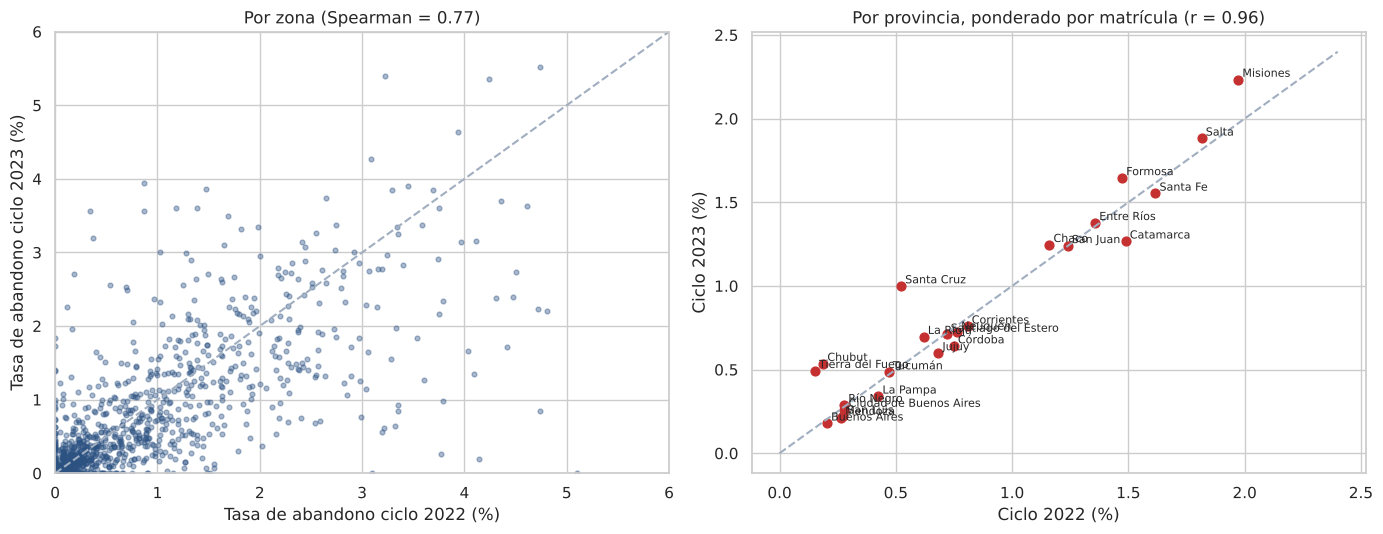

,ciclo_2022,ciclo_2023
provincia,,
Buenos Aires,0.20,0.18
Mendoza,0.26,0.21
San Luis,0.27,0.22
Ciudad de Buenos Aires,0.28,0.26
Río Negro,0.28,0.29
La Pampa,0.42,0.34
Tucumán,0.47,0.48
Tierra del Fuego,0.15,0.49
Chubut,0.19,0.54


In [ ]:
tasa = df['tasa_abandono_pct']
rho_zonas = spearmanr(tasa, X['tasa_abandono_2022'], nan_policy='omit').correlation

w = df['matricula_expuesta']
ok = X['tasa_abandono_2022'].notna()
prov = pd.DataFrame({
    'ciclo_2022': (X.loc[ok, 'tasa_abandono_2022'] * w[ok]).groupby(df.loc[ok, 'provincia']).sum()
                  / w[ok].groupby(df.loc[ok, 'provincia']).sum(),
    'ciclo_2023': (tasa * w).groupby(df['provincia']).sum() / w.groupby(df['provincia']).sum(),
})
r_prov = prov.ciclo_2022.corr(prov.ciclo_2023)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
axes[0].scatter(X['tasa_abandono_2022'], tasa, s=12, alpha=0.4, color=AZUL)
axes[0].plot([0, 6], [0, 6], '--', color=GRIS)
axes[0].set(xlim=(0, 6), ylim=(0, 6), xlabel='Tasa de abandono ciclo 2022 (%)', ylabel='Tasa de abandono ciclo 2023 (%)',
            title=f'Por zona (Spearman = {rho_zonas:.2f})')
axes[1].scatter(prov.ciclo_2022, prov.ciclo_2023, s=40, color=ROJO)
for p, r in prov.iterrows():
    axes[1].annotate(p, (r.ciclo_2022, r.ciclo_2023), fontsize=8, xytext=(3, 2), textcoords='offset points')
axes[1].plot([0, 2.4], [0, 2.4], '--', color=GRIS)
axes[1].set(xlabel='Ciclo 2022 (%)', ylabel='Ciclo 2023 (%)', title=f'Por provincia, ponderado por matrícula (r = {r_prov:.2f})')
plt.tight_layout(); plt.show()
display(prov.round(2).sort_values('ciclo_2023'))

- **Persistencia:** las zonas con abandono alto en 2022 lo siguen teniendo en 2023. El abandono es un rasgo **persistente** de cada zona, no un valor puntual, y la tasa del año anterior debería ser un buen predictor.
- **Registro por provincia:** a nivel provincial, la tasa es casi idéntica entre los dos ciclos (Buenos Aires sigue siendo la más baja; Misiones, Salta y Formosa, las más altas). Esto es **consistente con la hipótesis de registro dispar**: cada provincia mantiene su propio nivel. No lo prueba, porque también podría ser una diferencia real y estable, pero indica que la tasa del año anterior captura ese "estilo" provincial sin necesidad de usar la provincia como predictor.
- Las excepciones son las provincias patagónicas más chicas (Chubut, Santa Cruz, Tierra del Fuego), donde la tasa cambia bastante de un año a otro.

---
### 5. Esquema de validación
1. **Prueba final:** reservamos el 20% de las provincias, que no se usan para elegir el modelo.
2. **Selección del modelo:** validación cruzada de 5 grupos con las provincias restantes (`GroupKFold`): en cada vuelta el modelo se evalúa en provincias que no vio.

Todas las filas de una provincia quedan siempre del mismo lado.

In [ ]:
y = df['y_log']
grupos = df['provincia']
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
idx_tr, idx_te = next(gss.split(X, y, groups=grupos))
X_tr, X_te, y_tr, y_te = X.iloc[idx_tr], X.iloc[idx_te], y.iloc[idx_tr], y.iloc[idx_te]
g_tr = grupos.iloc[idx_tr]
assert set(g_tr).isdisjoint(set(grupos.iloc[idx_te]))
print(f'Entrenamiento: {len(idx_tr)} zonas de {g_tr.nunique()} provincias')
print(f'Prueba:        {len(idx_te)} zonas de {grupos.iloc[idx_te].nunique()} provincias → {sorted(grupos.iloc[idx_te].unique())}')

Entrenamiento: 714 zonas de 19 provincias
Prueba:        422 zonas de 5 provincias → ['Buenos Aires', 'Formosa', 'La Rioja', 'Salta', 'San Luis']


---
### 6. Entrenamiento y comparación de modelos

#### 6.1. Modelos candidatos
- **Línea base:** predecir siempre la mediana. Un modelo que no le gana no sirve.
- **Ridge:** regresión lineal regularizada, simple e interpretable.
- **Random Forest** y **Gradient Boosting:** modelos de árboles que captan relaciones no lineales, como el aplanamiento en los quintiles medios que vimos en la entrega 2.

Cada modelo es un `Pipeline` que imputa faltantes con la mediana (agregando indicadores de qué se imputó) y, en Ridge, estandariza. Así lo aprendido sale solo de los datos de entrenamiento de cada vuelta.

In [ ]:
def pipeline(modelo, escalar=False):
    pasos = [('imputar', SimpleImputer(strategy='median', add_indicator=True))]
    if escalar:
        pasos.append(('escalar', StandardScaler()))
    pasos.append(('modelo', modelo))
    return Pipeline(pasos)

candidatos = {
    'Línea base (mediana)': pipeline(DummyRegressor(strategy='median')),
    'Ridge': pipeline(Ridge(alpha=10), escalar=True),
    'Random Forest': pipeline(RandomForestRegressor(n_estimators=400, min_samples_leaf=10, max_features=0.5,
                                                    random_state=SEED, n_jobs=-1)),
    'Gradient Boosting': pipeline(HistGradientBoostingRegressor(max_depth=3, learning_rate=0.03, max_iter=300,
                                                                random_state=SEED)),
}

def a_pct(pred_log):
    return np.clip(np.expm1(pred_log), 0, 100)

def metricas(y_log_real, pred_log, umbral_pct):
    real, pred = np.expm1(np.asarray(y_log_real)), a_pct(pred_log)
    alto = real >= umbral_pct
    constante = np.ptp(pred) < 1e-9          # la línea base no ordena: Spearman y recall del top 25% no aplican
    top = pred >= np.quantile(pred, 0.75)
    return {'MAE_pp': mean_absolute_error(real, pred),
            'R2_log': r2_score(y_log_real, np.log1p(pred)),
            'Spearman': np.nan if constante else spearmanr(real, pred).correlation,
            'Recall_top25': np.nan if constante else (top & alto).sum() / max(alto.sum(), 1)}

def validar(nombre, modelo, columnas):
    filas = []
    for tr, va in GroupKFold(n_splits=5).split(X_tr, y_tr, g_tr):
        m = sklearn.base.clone(modelo).fit(X_tr.iloc[tr][columnas], y_tr.iloc[tr])
        umbral = np.expm1(y_tr.iloc[tr]).quantile(0.75)          # P75 aprendido solo en entrenamiento
        filas.append(metricas(y_tr.iloc[va], m.predict(X_tr.iloc[va][columnas]), umbral))
    r = pd.DataFrame(filas)
    return {'modelo': nombre, **r.mean().to_dict(), 'MAE_desvio': r['MAE_pp'].std()}

#### 6.2. ¿Cuánto aporta el ciclo anterior?
Comparamos tres conjuntos de variables: solo contexto 2023, contexto + matrícula 2023, y contexto + matrícula 2023 + abandono del ciclo 2022.

In [ ]:
CONTEXTO = [c for c in X.columns if not c.endswith(('_2022', '_2022_sec', '_2023'))]
MATRICULA_23 = ['pct_sobreedad_2023', 'pct_repitentes_2023']
CICLO_22 = ['tasa_abandono_2022', 'tasa_abandono_2022_sec']
conjuntos = {
    'A. Contexto 2023': CONTEXTO,
    'B. + Matrícula 2023': CONTEXTO + MATRICULA_23,
    'C. + Abandono ciclo 2022': CONTEXTO + MATRICULA_23 + CICLO_22,
}
resultados = []
for nombre_conj, cols in conjuntos.items():
    for nombre_mod, mod in candidatos.items():
        if nombre_mod.startswith('Línea base') and nombre_conj != 'A. Contexto 2023':
            continue
        r = validar(nombre_mod, mod, cols)
        r['variables'] = nombre_conj if not nombre_mod.startswith('Línea base') else '—'
        resultados.append(r)
cv = pd.DataFrame(resultados).set_index(['variables', 'modelo'])
cv.round(3)

MAE_pp  R2_log  Spearman  \
variables                modelo                                           
—                        Línea base (mediana)   0.771  -0.097       NaN   
A. Contexto 2023         Ridge                  0.780  -0.111     0.316   
                         Random Forest          0.714   0.059     0.412   
                         Gradient Boosting      0.732   0.008     0.388   
B. + Matrícula 2023      Ridge                  0.764  -0.082     0.384   
                         Random Forest          0.691   0.120     0.493   
                         Gradient Boosting      0.721   0.050     0.441   
C. + Abandono ciclo 2022 Ridge                  0.670   0.228     0.633   
                         Random Forest          0.523   0.454     0.712   
                         Gradient Boosting      0.536   0.437     0.701   

                                               Recall_top25  MAE_desvio  
variables                modelo                                          
—                        Línea base (mediana)           NaN       0.231  
A. Contexto 2023         Ridge                        0.357       0.222  
                         Random Forest                0.371       0.194  
                         Gradient Boosting            0.348       0.182  
B. + Matrícula 2023      Ridge                        0.425       0.205  
                         Random Forest                0.435       0.187  
                         Gradient Boosting            0.433       0.173  
C. + Abandono ciclo 2022 Ridge                        0.631       0.265  
                         Random Forest                0.647       0.139  
                         Gradient Boosting            0.610       0.133

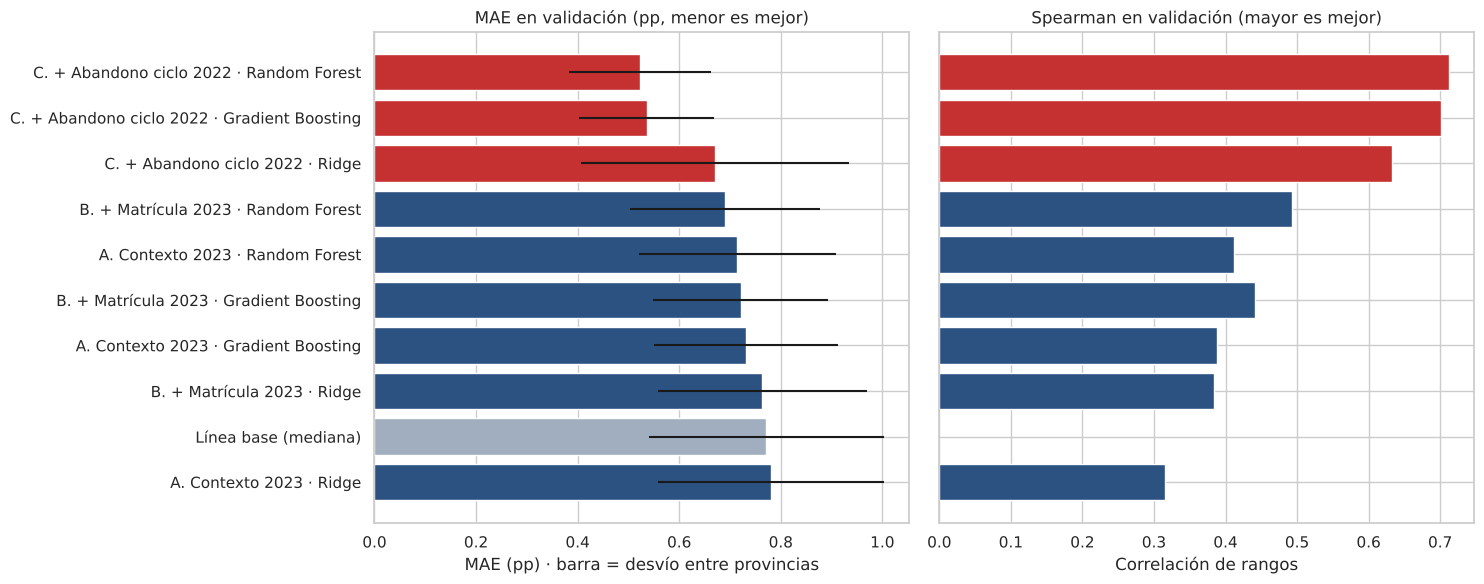

In [ ]:
orden = cv.sort_values('MAE_pp', ascending=False)
etiquetas = [f'{v} · {m}' if v != '—' else m for v, m in orden.index]
colores = [ROJO if 'C.' in v else (AZUL if v != '—' else GRIS) for v, _ in orden.index]
fig, axes = plt.subplots(1, 2, figsize=(15, 6), sharey=True)
axes[0].barh(etiquetas, orden['MAE_pp'], xerr=orden['MAE_desvio'], color=colores)
axes[0].set(title='MAE en validación (pp, menor es mejor)', xlabel='MAE (pp) · barra = desvío entre provincias')
axes[1].barh(etiquetas, orden['Spearman'], color=colores)
axes[1].set(title='Spearman en validación (mayor es mejor)', xlabel='Correlación de rangos')
plt.tight_layout(); plt.show()

- Con **solo variables de contexto** (A y B), los modelos le ganan apenas a la línea base: predecir el abandono en provincias que el modelo nunca vio es muy difícil, porque cada provincia tiene su propio nivel.
- Sumar el **abandono del ciclo anterior** (C, en rojo) cambia el resultado: el error baja mucho y el modelo pasa a ordenar bien las zonas. Es la mejora más importante de esta entrega y responde a la sugerencia de la devolución.
- Los modelos de **árboles** funcionan mejor que Ridge, coherente con las relaciones no lineales del EDA.

#### 6.3. Verificación: ¿las variables provinciales son un identificador encubierto?
Repetimos el mejor modelo sumando desempleo y salario provincial y las variables de región.

In [ ]:
regiones = pd.get_dummies(df['region_eph'], prefix='region', dtype=float)
X_prov = X.join(df[['desempleo_prov_2023', 'remun_rel_2024']].astype(float)).join(regiones)
PROVINCIALES = ['desempleo_prov_2023', 'remun_rel_2024'] + list(regiones.columns)
X_tr_prov = X_prov.iloc[idx_tr]
cols_c = conjuntos['C. + Abandono ciclo 2022']
comparacion = []
for etiqueta, XX, cols in [('Sin variables provinciales', X_tr, cols_c),
                           ('Con variables provinciales', X_tr_prov, cols_c + [c for c in PROVINCIALES if c in X_prov])]:
    filas = []
    for tr, va in GroupKFold(n_splits=5).split(XX, y_tr, g_tr):
        m = sklearn.base.clone(candidatos['Random Forest']).fit(XX.iloc[tr][cols], y_tr.iloc[tr])
        filas.append(metricas(y_tr.iloc[va], m.predict(XX.iloc[va][cols]), np.expm1(y_tr.iloc[tr]).quantile(0.75)))
    comparacion.append({'variables': etiqueta, **pd.DataFrame(filas).mean().to_dict()})
pd.DataFrame(comparacion).set_index('variables').round(3)

,MAE_pp,R2_log,Spearman,Recall_top25
variables,,,,
Sin variables provinciales,0.523,0.454,0.712,0.647
Con variables provinciales,0.533,0.442,0.708,0.641


Sumar las variables provinciales no mejora el modelo en provincias nuevas: solo le permiten "reconocer" la provincia, algo que no sirve fuera del entrenamiento. Confirmamos la decisión de dejarlas afuera.

#### 6.4. Modelo elegido
Elegimos el modelo con **menor MAE promedio** en validación, siempre que también mejore el Spearman respecto de la línea base.

In [ ]:
mejor_var, mejor_mod = cv['MAE_pp'].idxmin()
COLUMNAS = conjuntos[mejor_var]
print(f'Modelo elegido: {mejor_mod} con variables "{mejor_var}" ({len(COLUMNAS)} variables)')
print(cv.loc[(mejor_var, mejor_mod)].round(3).to_string())

Modelo elegido: Random Forest con variables "C. + Abandono ciclo 2022" (20 variables)
MAE_pp          0.523
R2_log          0.454
Spearman        0.712
Recall_top25    0.647
MAE_desvio      0.139


---
### 7. Evaluación en provincias de prueba
Entrenamos el modelo elegido con todas las provincias de entrenamiento y lo evaluamos una sola vez en las provincias reservadas.

In [ ]:
modelo_final = sklearn.base.clone(candidatos[mejor_mod]).fit(X_tr[COLUMNAS], y_tr)
umbral_alto = float(np.expm1(y_tr).quantile(0.75))        # P75 de entrenamiento
pred_te_log = modelo_final.predict(X_te[COLUMNAS])
base_te = sklearn.base.clone(candidatos['Línea base (mediana)']).fit(X_tr[COLUMNAS], y_tr).predict(X_te[COLUMNAS])
modelo_a = sklearn.base.clone(candidatos[mejor_mod]).fit(X_tr[conjuntos['A. Contexto 2023']], y_tr)
pred_a = modelo_a.predict(X_te[conjuntos['A. Contexto 2023']])

tabla_test = pd.DataFrame({
    'Línea base (mediana)': metricas(y_te, base_te, umbral_alto),
    f'{mejor_mod} · solo contexto (A)': metricas(y_te, pred_a, umbral_alto),
    f'{mejor_mod} · modelo final': metricas(y_te, pred_te_log, umbral_alto),
}).T
print(f'Umbral de alto riesgo (P75 de entrenamiento): {umbral_alto:.2f}%')
tabla_test.round(3)

Umbral de alto riesgo (P75 de entrenamiento): 1.39%


,MAE_pp,R2_log,Spearman,Recall_top25
Línea base (mediana),0.602,-0.176,NaN,NaN
Random Forest · solo contexto (A),0.585,-0.151,0.423,0.522
Random Forest · modelo final,0.355,0.517,0.693,0.870


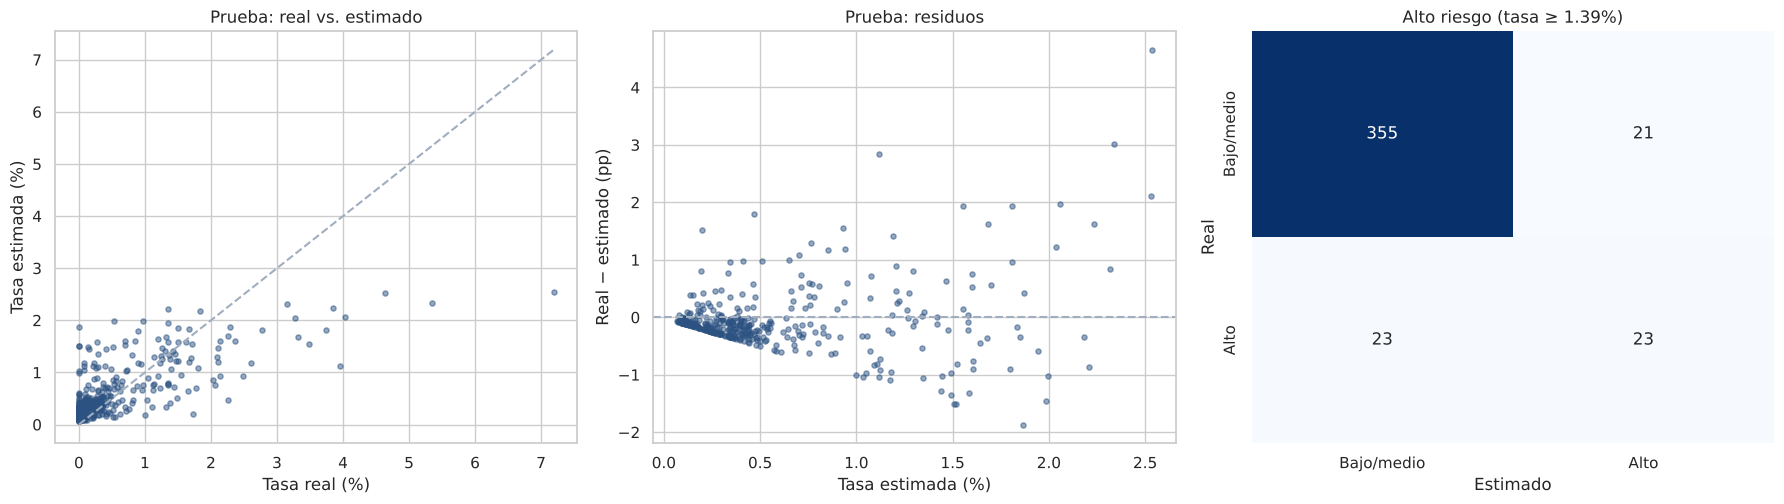

Alto riesgo derivado de la regresión → accuracy 0.90, precisión 0.52, recall 0.50, F1 0.51


In [ ]:
real_te, pred_te = np.expm1(y_te.values), a_pct(pred_te_log)
fig, axes = plt.subplots(1, 3, figsize=(18, 5.2))
axes[0].scatter(real_te, pred_te, s=14, alpha=0.5, color=AZUL)
lim = max(real_te.max(), pred_te.max())
axes[0].plot([0, lim], [0, lim], '--', color=GRIS)
axes[0].set(xlabel='Tasa real (%)', ylabel='Tasa estimada (%)', title='Prueba: real vs. estimado')
axes[1].scatter(pred_te, real_te - pred_te, s=14, alpha=0.5, color=AZUL)
axes[1].axhline(0, color=GRIS, ls='--')
axes[1].set(xlabel='Tasa estimada (%)', ylabel='Real − estimado (pp)', title='Prueba: residuos')
cm = confusion_matrix(real_te >= umbral_alto, pred_te >= umbral_alto)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[2],
            xticklabels=['Bajo/medio', 'Alto'], yticklabels=['Bajo/medio', 'Alto'])
axes[2].set(xlabel='Estimado', ylabel='Real', title=f'Alto riesgo (tasa ≥ {umbral_alto:.2f}%)')
plt.tight_layout(); plt.show()

alto_real, alto_pred = real_te >= umbral_alto, pred_te >= umbral_alto
print(f'Alto riesgo derivado de la regresión → accuracy {accuracy_score(alto_real, alto_pred):.2f}, '
      f'precisión {precision_score(alto_real, alto_pred):.2f}, recall {recall_score(alto_real, alto_pred):.2f}, '
      f'F1 {f1_score(alto_real, alto_pred):.2f}')

**Lectura de los resultados:**
- El modelo final reduce el **MAE de 0,60 a 0,36 pp** (−41% respecto de la línea base) y explica cerca de la mitad de la variabilidad (**R² = 0,52**). Sin el ciclo anterior, el mismo modelo prácticamente no le gana a la línea base (R² negativo).
- Para **priorizar**, lo importante es el orden: el 25% de zonas que el modelo marca como más riesgosas incluye **el 87% de las zonas de alto riesgo reales** de las provincias de prueba.
- Si en cambio usamos un **umbral fijo** (tasa estimada ≥ 1,39%), detecta la mitad de las zonas de alto riesgo (recall 0,50, precisión 0,52). La accuracy de 0,90 es engañosa: la mayoría de las zonas de prueba son de riesgo bajo.
- En el gráfico real vs. estimado, el modelo **subestima las tasas muy altas** (los puntos de la derecha quedan debajo de la diagonal): los casos extremos son difíciles de anticipar y la estimación tiende al promedio.
- Ojo: 319 de las 422 zonas de prueba son de **Buenos Aires**, que tiene tasas bajas. Por eso las métricas de prueba se ven mejor que las de validación, que son una referencia más prudente (MAE 0,52 pp, R² 0,45).

#### 7.1. ¿Qué predijo el modelo? Resultados por provincia y por zona
Para cada una de las 422 zonas de prueba el modelo estima una tasa de abandono. Abajo las resumimos por provincia y mostramos las zonas que el modelo marcaría como prioritarias.

In [ ]:
pred_zonas = df.iloc[idx_te][['provincia', 'departamento', 'sector', 'ambito', 'matricula_expuesta']].copy()
pred_zonas['tasa_real_pct'] = real_te
pred_zonas['tasa_estimada_pct'] = pred_te

def ponderada(g, col):
    return (g[col] * g['matricula_expuesta']).sum() / g['matricula_expuesta'].sum()

por_provincia = pred_zonas.groupby('provincia').apply(lambda g: pd.Series({
    'zonas': len(g),
    'tasa_real_%': ponderada(g, 'tasa_real_pct'),
    'tasa_estimada_%': ponderada(g, 'tasa_estimada_pct'),
})).sort_values('tasa_real_%')
por_provincia['zonas'] = por_provincia['zonas'].astype(int)
display(por_provincia.round(2))

prioridad = pred_zonas.sort_values('tasa_estimada_pct', ascending=False).head(15).copy()
prioridad['es_alto_riesgo_real'] = np.where(prioridad['tasa_real_pct'] >= umbral_alto, 'Sí', 'No')
print(f'Zonas que el modelo marca como más riesgosas (umbral de alto riesgo: {umbral_alto:.2f}%)')
display(prioridad[['provincia', 'departamento', 'sector', 'ambito', 'tasa_estimada_pct', 'tasa_real_pct', 'es_alto_riesgo_real']]
        .round(2).reset_index(drop=True))
print(f"De las 15 zonas priorizadas, {(prioridad['es_alto_riesgo_real'] == 'Sí').sum()} tienen realmente abandono alto.")

,zonas,tasa_real_%,tasa_estimada_%
provincia,,,
Buenos Aires,319,0.18,0.33
San Luis,18,0.22,0.45
La Rioja,25,0.70,0.51
Formosa,20,1.65,1.15
Salta,40,1.88,1.41


Zonas que el modelo marca como más riesgosas (umbral de alto riesgo: 1.39%)


,provincia,departamento,sector,ambito,tasa_estimada_pct,tasa_real_pct,es_alto_riesgo_real
0,Formosa,RAMON LISTA,Estatal,Rural,2.54,7.19,Sí
1,Formosa,PATIÑO,Estatal,Rural,2.53,4.63,Sí
2,Formosa,BERMEJO,Estatal,Rural,2.34,5.35,Sí
3,Salta,RIVADAVIA,Estatal,Rural,2.32,3.15,Sí
4,Salta,GENERAL JOSE DE SAN MARTIN,Estatal,Rural,2.23,3.85,Sí
5,Salta,GENERAL GUEMES,Estatal,Rural,2.21,1.35,No
6,Formosa,PIRANE,Estatal,Rural,2.18,1.83,Sí
7,Salta,RIVADAVIA,Estatal,Urbano,2.06,4.03,Sí
8,Salta,CAFAYATE,Estatal,Urbano,2.04,3.27,Sí
9,Buenos Aires,RIVADAVIA,Estatal,Urbano,1.99,0.98,No


De las 15 zonas priorizadas, 10 tienen realmente abandono alto.


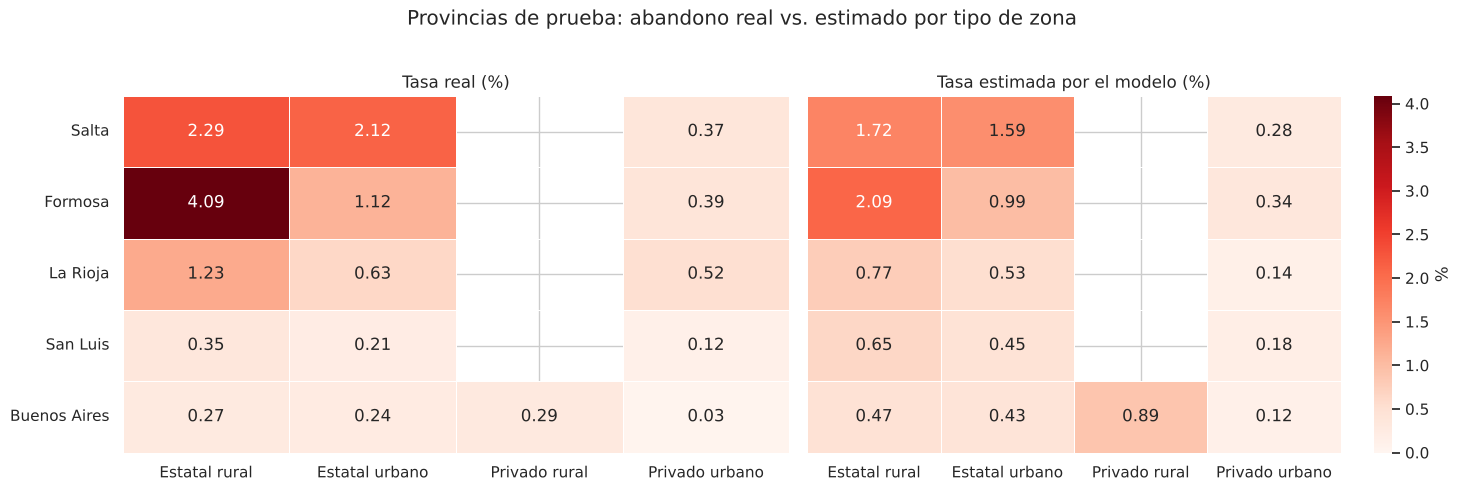

In [ ]:
# Mapa de calor 1: provincia × tipo de zona, tasa real vs. estimada (misma escala de color)
pred_zonas['tipo_zona'] = pred_zonas['sector'] + ' ' + pred_zonas['ambito'].str.lower()
orden_prov = por_provincia.index.tolist()[::-1]
tablas = {}
for col, titulo in [('tasa_real_pct', 'Tasa real (%)'), ('tasa_estimada_pct', 'Tasa estimada por el modelo (%)')]:
    tablas[titulo] = (pred_zonas.groupby(['provincia', 'tipo_zona'])
                      .apply(lambda g: ponderada(g, col)).unstack().reindex(orden_prov))
vmax = max(t.max().max() for t in tablas.values())
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8), sharey=True)
for ax, (titulo, t) in zip(axes, tablas.items()):
    sns.heatmap(t, annot=True, fmt='.2f', cmap='Reds', vmin=0, vmax=vmax, linewidths=0.5,
                cbar=ax is axes[1], cbar_kws={'label': '%'}, ax=ax)
    ax.set(title=titulo, xlabel='', ylabel='')
    ax.tick_params(axis='x', rotation=0)
plt.suptitle('Provincias de prueba: abandono real vs. estimado por tipo de zona', y=1.02)
plt.tight_layout(); plt.show()

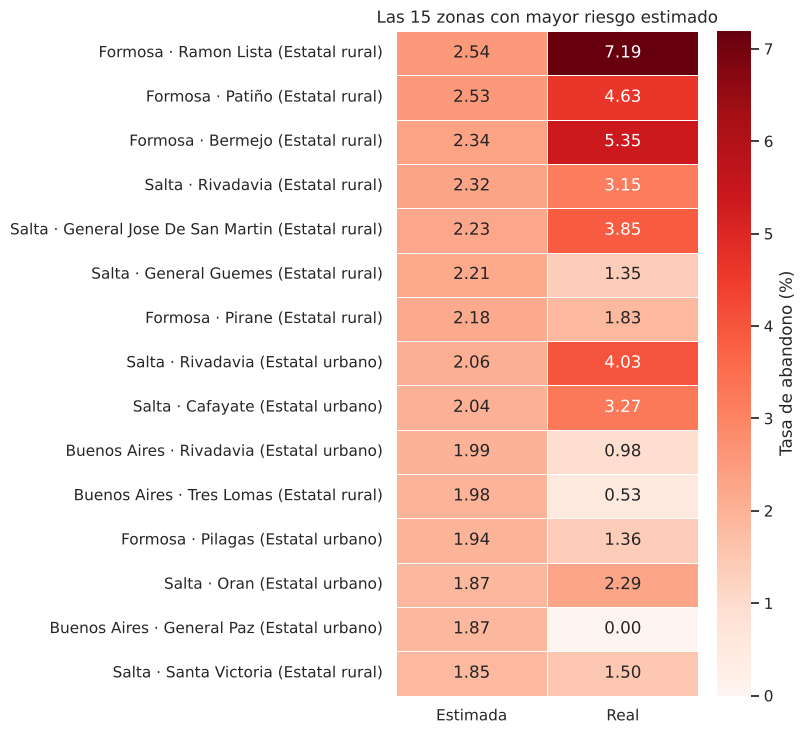

In [ ]:
# Mapa de calor 2: las 15 zonas que el modelo prioriza
top = prioridad.copy()
top['zona'] = (top['provincia'] + ' · ' + top['departamento'].str.title() + ' (' +
               top['sector'] + ' ' + top['ambito'].str.lower() + ')')
calor = top.set_index('zona')[['tasa_estimada_pct', 'tasa_real_pct']]
calor.columns = ['Estimada', 'Real']
fig, ax = plt.subplots(figsize=(8, 7.5))
sns.heatmap(calor, annot=True, fmt='.2f', cmap='Reds', linewidths=0.5, cbar_kws={'label': 'Tasa de abandono (%)'}, ax=ax)
ax.set(title='Las 15 zonas con mayor riesgo estimado', xlabel='', ylabel='')
plt.tight_layout(); plt.show()

**Lectura:**
- **Por provincia**, el modelo ordena bien: identifica que Salta y Formosa tienen mucho más abandono que Buenos Aires y San Luis, aunque nunca vio esas provincias. Pero **acerca los valores al centro**: sobreestima las provincias de abandono bajo y subestima las de abandono alto.
- **Por tipo de zona**, el primer mapa de calor muestra el mismo patrón que el real: el abandono se concentra en las zonas **estatales**, sobre todo **rurales**, de Salta y Formosa.
- Los casilleros vacíos son combinaciones que no existen en esa provincia (por ejemplo, escuelas privadas rurales).
- **Las zonas priorizadas:** 10 de las 15 zonas que el modelo marca como más riesgosas tienen realmente abandono alto. Son, en su mayoría, zonas estatales rurales de Formosa y Salta. El modelo se equivoca en el valor exacto (por ejemplo, estima 2,5% en Ramón Lista cuando la tasa real es 7,2%), pero **la ubica primera en la lista**, que es lo que importa para decidir dónde intervenir.

---
### 8. Importancia de variables y análisis de errores
Usamos **importancia por permutación** en las provincias de prueba: cuánto empeora el error si desordenamos una variable. No implica causalidad.

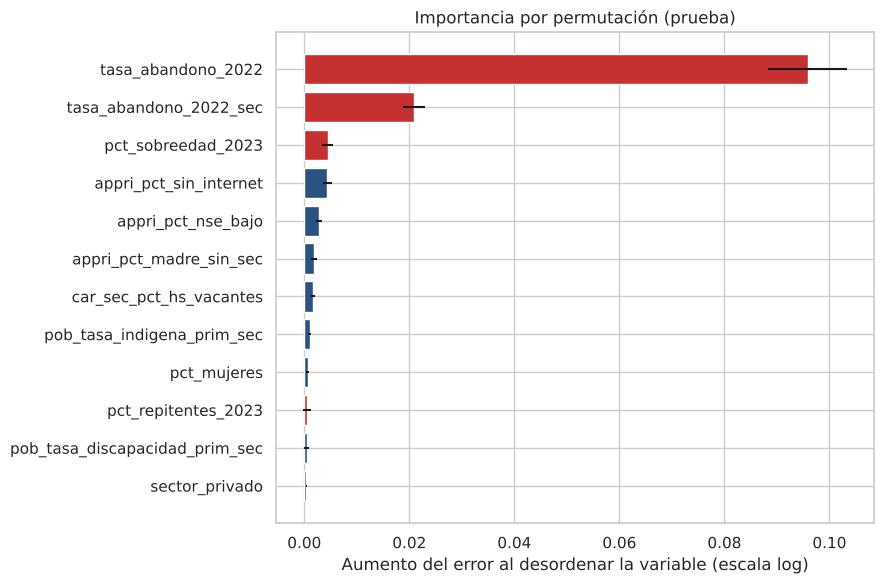

In [ ]:
imp = permutation_importance(modelo_final, X_te[COLUMNAS], y_te, scoring='neg_mean_absolute_error',
                             n_repeats=10, random_state=SEED)
importancia = (pd.DataFrame({'variable': COLUMNAS, 'importancia': imp.importances_mean, 'desvio': imp.importances_std})
                 .sort_values('importancia', ascending=True).tail(12))
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(importancia['variable'], importancia['importancia'], xerr=importancia['desvio'],
        color=[ROJO if v in CICLO_22 + MATRICULA_23 else AZUL for v in importancia['variable']])
ax.set(title='Importancia por permutación (prueba)', xlabel='Aumento del error al desordenar la variable (escala log)')
plt.tight_layout(); plt.show()

In [ ]:
errores = df.iloc[idx_te][['provincia', 'departamento', 'sector', 'ambito']].copy()
errores['tasa_real'] = real_te
errores['tasa_estimada'] = pred_te
errores['error_abs'] = (errores.tasa_real - errores.tasa_estimada).abs()
resumen = pd.concat([errores.groupby(col)['error_abs'].agg(['count', 'mean']).rename(columns={'count': 'zonas', 'mean': 'MAE_pp'})
                     .assign(dimension=col) for col in ['provincia', 'sector', 'ambito']])
display(resumen.round(3))
print('Zonas con mayor error:')
errores.sort_values('error_abs', ascending=False).head(8).round(2)

,zonas,MAE_pp,dimension
Buenos Aires,319,0.277,provincia
Formosa,20,1.047,provincia
La Rioja,25,0.521,provincia
Salta,40,0.538,provincia
San Luis,18,0.341,provincia
Estatal,324,0.427,sector
Privado,98,0.117,sector
Rural,158,0.525,ambito
Urbano,264,0.254,ambito


Zonas con mayor error:


,provincia,departamento,sector,ambito,tasa_real,tasa_estimada,error_abs
676,Formosa,RAMON LISTA,Estatal,Rural,7.19,2.54,4.66
654,Formosa,BERMEJO,Estatal,Rural,5.35,2.34,3.02
664,Formosa,MATACOS,Estatal,Rural,3.95,1.11,2.83
666,Formosa,PATIÑO,Estatal,Rural,4.63,2.53,2.10
968,Salta,RIVADAVIA,Estatal,Urbano,4.03,2.06,1.97
659,Formosa,FORMOSA,Estatal,Rural,3.49,1.55,1.94
751,La Rioja,CHAMICAL,Estatal,Rural,3.74,1.81,1.93
131,Buenos Aires,GENERAL PAZ,Estatal,Urbano,0.00,1.87,1.87


- La **tasa del ciclo anterior** es, por lejos, la variable más importante, seguida por las de sobreedad y vulnerabilidad del hogar.
- El error es mayor en el **sector estatal** y en el **ámbito rural**, que son justamente las zonas con más abandono y más variabilidad.
- Las zonas con mayor error suelen ser casos con tasas muy altas o que cambiaron mucho respecto del año anterior.

---
### 9. Reflexión crítica y posibles mejoras

**Qué funcionó**
- Incorporar el **ciclo anterior** fue la mejora decisiva. Sin él, ningún modelo le ganaba con claridad a la línea base en provincias nuevas; con él, el error baja un 30% en validación y el modelo ordena bien las zonas de más a menos riesgo.
- Sacar las **variables provinciales** evitó que el modelo memorizara provincias y no empeoró los resultados en provincias nuevas.
- La validación por provincia es exigente, pero da una idea realista de cómo funcionaría el modelo en una jurisdicción nueva.

**Limitaciones**
- Gran parte del poder predictivo viene de la **persistencia**: el modelo anticipa bien dónde el abandono se mantiene, pero le cuesta anticipar zonas que **empeoran** de un año a otro.
- **Subestima las tasas muy altas**, que son justamente las más preocupantes. Por eso funciona mejor para **ordenar** zonas (priorizar el 25% más alto) que para decidir con un umbral fijo, donde detecta solo la mitad de las zonas de alto riesgo.
- La tasa mide **salidos sin pase registrados**, no el abandono definitivo, y las provincias podrían registrarlo de forma distinta.
- Con 24 provincias, las métricas en prueba dependen de qué provincias quedaron reservadas y deben tomarse como aproximadas.
- El análisis es **territorial**: no dice nada sobre alumnos individuales.

**Posibles mejoras**
1. Sumar más ciclos (por ejemplo 2019) para modelar **tendencias**, evitando 2020 y 2021 por la pandemia.
2. Entrenar con **ponderación por matrícula** para priorizar el error en zonas grandes.
3. Probar un modelo para predecir el **ciclo siguiente** (2024) con la información de 2023: es el uso real que tendría el Ministerio.
4. Ajustar **hiperparámetros** con una búsqueda más amplia y validación anidada.
5. Analizar por separado **primaria y secundaria**, donde se concentra el abandono.

---
### 10. Persistencia del modelo y prueba de carga sin reentrenar
Guardamos el `Pipeline` entrenado (imputación + modelo) junto con la lista de variables, el umbral de alto riesgo y las métricas, en un archivo `.joblib`. Después lo cargamos en un **proceso de Python nuevo**, sin reentrenar, y comprobamos que da las mismas predicciones.

In [ ]:
paquete = {
    'pipeline': modelo_final,
    'variables': COLUMNAS,
    'objetivo': 'log1p(tasa de abandono en %); usar np.expm1 para volver a %',
    'umbral_alto_riesgo_pct': umbral_alto,
    'modelo': mejor_mod,
    'provincias_entrenamiento': sorted(g_tr.unique()),
    'provincias_prueba': sorted(grupos.iloc[idx_te].unique()),
    'metricas_prueba': tabla_test.loc[f'{mejor_mod} · modelo final'].round(4).to_dict(),
    'versiones': {'python': platform.python_version(), 'sklearn': sklearn.__version__},
}
joblib.dump(paquete, CARPETA / 'modelo_abandono.joblib')
X_te[COLUMNAS].head(5).to_csv(CARPETA / 'ejemplo_entrada.csv', index=False)
(CARPETA / 'variables.json').write_text(json.dumps(COLUMNAS, ensure_ascii=False, indent=2), encoding='utf-8')
print('Guardado en', CARPETA.resolve())

Guardado en /tmp/claude-0/-home-claude/f66fe211-8073-5cc0-b6d8-acd536b1b11c/scratchpad/e3/run/modelo_entrega3


In [ ]:
script = '''
import joblib, numpy as np, pandas as pd
p = joblib.load("modelo_abandono.joblib")
x = pd.read_csv("ejemplo_entrada.csv")[p["variables"]]
tasa = np.clip(np.expm1(p["pipeline"].predict(x)), 0, 100)
pd.DataFrame({"tasa_estimada_pct": tasa, "alto_riesgo": (tasa >= p["umbral_alto_riesgo_pct"]).astype(int)}).to_csv("prediccion_recargada.csv", index=False)
print("Modelo cargado y usado sin reentrenar.")
'''
proc = subprocess.run([sys.executable, '-c', script], cwd=CARPETA, capture_output=True, text=True, check=True)
print(proc.stdout)
recargada = pd.read_csv(CARPETA / 'prediccion_recargada.csv')
en_memoria = a_pct(modelo_final.predict(X_te[COLUMNAS].head(5)))
np.testing.assert_allclose(recargada['tasa_estimada_pct'], en_memoria, rtol=1e-9)
print('Las predicciones del modelo recargado coinciden con las del modelo en memoria.')
recargada.round(3)

Modelo cargado y usado sin reentrenar.

Las predicciones del modelo recargado coinciden con las del modelo en memoria.


,tasa_estimada_pct,alto_riesgo
0,0.192,0
1,0.298,0
2,0.125,0
3,1.265,0
4,1.296,0


El modelo queda guardado en `modelo_entrega3/modelo_abandono.joblib`, listo para usarse en la próxima entrega sin reentrenar. Para usarlo: cargar el archivo con `joblib.load`, pasarle una tabla con las columnas de `variables.json` y aplicar `np.expm1` a la predicción para obtener la tasa en %.